# ICT-36c — Pont F-Lens x Higuchi : quatre instruments de dimensionnalite face a un terrain a facteurs controles

Ce notebook est le premier livrable du grain [#20463](https://github.com/jsboige/CoursIA/issues/20463) : la
distillation de **Subramani et al. 2026** (*LSD/MEG, bioRxiv 10.64898/2026.01.28.702361*) croisee avec la
lentille **F-Lens** de [ICT-36](ICT-36-FLens-FactoredGeometry-Python.ipynb).

**Navigation** : [Index ICT-Series](README.md) | [<< ICT-36b](ICT-36b-RuzsaOnFactorGeometry-Python.ipynb) | [>> ICT-36d](ICT-36d-FLens-DecorrelationTemporelle-Python.ipynb)

**Trois litteratures, une tension.**

1. **Subramani et al. 2026** mesurent sur MEG la complexite de signaux neuronaux sous LSD avec deux
   instruments de la litterature neuro-complexite : la **dimension fractale de Higuchi (HFD)** et la
   **complexite Lempel-Ziv (LZC)**, et raportent une **augmentation de dimensionnalite effective** sous
   psychedele.
2. **Shai et al. 2024** (PNAS) montrent la direction inverse chez les LLM : a l'entrainement repete, les
   representations **s'effondrent** vers un ou deux facteurs dominants (dimensionnalite effective en chute).
3. **F-Lens (ICT-36)** lit la geometrie factorisee d'une representation : dimension effective **NC@p**
   (nombre de composantes pour p % de variance cumulee) et alignement des sous-espaces principaux.

**Question pre-enregistree** (falsifiable, tranchee par la mesure ci-dessous, pas par l'intuition) : sur un
terrain synthetique GHMM ou le nombre de facteurs actifs k varie de 0 (bruit pur) a 5, quels instruments
suivent k, et en quel sens ? En particulier : la HFD — l'instrument du papier MEG — mesure-t-elle le **nombre
de facteurs partages**, ou autre chose ?

**Perimetre honnete du terrain.** Le dataset MEG-17 du papier n'a pas pu etre etabli depuis ce siege
(bioRxiv derriere un mur anti-robot, OpenNeuro 404) : ce notebook execute le **repli synthetique du
protocole** — terrain a facteurs controles, verite terrain exacte. Ce qu'il etablit : la **reponse
calibree des instruments** sur terrain connu. Ce qu'il n'etablit pas : quoi que ce soit de neuro.

**Organes consommes, jamais reimplementes** (regle organ-first, #13564) :
[`ict/flens_traces.py`](ict/flens_traces.py) (`measure_flens`, `prompt_geometry`, `null_pairs`) et
[`ict/factor_geometry.py`](ict/factor_geometry.py) (`weighted_pca`). La HFD et la LZC viennent de la
librairie reelle du domaine, `antropy` (le papier utilise `antropy.higuchi_fd`, Kmax=18 — regle F :
l'outil reel est installe et invoque, verdict SOTA-OK).

## 1. Mise en place

Imports et racine canonique de la serie (idiome ICT-36) : on remonte les parents depuis le dossier du
notebook jusqu'au package `ict/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import antropy as ent
import matplotlib.pyplot as plt

ICT_ROOT = Path.cwd()
while not (ICT_ROOT / "ict" / "__init__.py").exists() and ICT_ROOT != ICT_ROOT.parent:
    ICT_ROOT = ICT_ROOT.parent
assert (ICT_ROOT / "ict" / "__init__.py").exists(), (
    f"package ict/ introuvable en remontant depuis {Path.cwd().name}")
if str(ICT_ROOT) not in sys.path:
    sys.path.insert(0, str(ICT_ROOT))

from ict.flens_traces import measure_flens, null_pairs
from ict.factor_geometry import weighted_pca

print("organe flens_traces resolu depuis le dossier", ICT_ROOT.name)
print("antropy importe : higuchi_fd, lziv_complexite disponibles")

# Constantes du terrain et des instruments.
K_MAX_HFD = 18          # Kmax du papier Subramani et al. 2026
T_TOKENS = 2048         # longueur temporelle par "prompt"
D_MODEL = 64            # nombre de canaux (dimension de representation)
RHO_AR = 0.9            # persistance AR(1) des facteurs
SIG_FACTOR = 1.0        # amplitude par facteur
SIG_NOISE = 0.32        # bruit de canal (~10 dB par facteur)
SEEDS = [0, 1, 7, 42]   # multi-seed (>= 4, discipline maison)
K_GRID = [0, 1, 2, 3, 4, 5]
N_PROMPTS = 3           # prompts par jeu (2 jeux -> 6 prompts par terrain)

organe flens_traces resolu depuis le dossier ICT-Series
antropy importe : higuchi_fd, lziv_complexite disponibles


## 2. Terrain GHMM synthetique — le contrat `dense` de l'organe

L'organe `measure_flens` consomme une capture dense `{"meta": ..., "prompts": {(set, i): {"tokens",
"resid"}}}`. On construit ce terrain **en memoire, dans le contrat exact** — l'organe n'est pas modifie,
pas plus qu'on ne recrit ses primitives.

Modele : chaque prompt est une trajectoire de **T = 2048 pas** dans un espace a **D = 64 canaux**.

- **Facteurs** : k processus AR(1) stationnaires (persistance 0.9) — la structure temporelle lisse.
- **Loadings** : colonnes orthonormales (QR) qui melangent les k facteurs vers les 64 canaux. Les prompts
  d'un ** meme jeu** partagent les memes loadings ; l'autre jeu en tire d'autres — c'est ce contraste que
  l'alignement intra/inter-jeux de F-Lens sait lire.
- **Observation** : `resid = loadings @ facteurs + bruit de canal`, bruit iid d'ecart-type 0.32 (~10 dB
  de rapport signal/bruit par facteur).

La verite terrain est exacte par construction : k = nombre de directions de variance structuree.

In [2]:
def make_factors(n_steps, k_active, rng, rho=RHO_AR):
    """k processus AR(1) stationnaires, normalises a un ecart-type unitaire."""
    eps = rng.standard_normal((n_steps, k_active))
    factors = np.empty_like(eps)
    factors[0] = eps[0]
    for t in range(1, n_steps):
        factors[t] = rho * factors[t - 1] + np.sqrt(1.0 - rho ** 2) * eps[t]
    return factors


def make_loadings(d_model, k_active, rng):
    """Matrice de loadings (d_model, k) a colonnes orthonormales (QR)."""
    q, _ = np.linalg.qr(rng.standard_normal((d_model, k_active)))
    return q


def build_terrain(k_active, seed, n_prompts=N_PROMPTS, t_tokens=T_TOKENS,
                  d_model=D_MODEL, sig_factor=SIG_FACTOR, sig_noise=SIG_NOISE):
    """Terrain GHMM a k facteurs actifs -> capture dense (contrat flens_traces).

    Jeux A et B : memes facteurs actifs, loadings differents — l'alignement
    intra-jeu doit depasser la nulle appariee, l'inter-jeu rester proche.
    """
    rng = np.random.default_rng(seed)
    loadings = {
        s: make_loadings(d_model, max(k_active, 1),
                         np.random.default_rng(seed * 100 + i))
        for i, s in enumerate("AB")
    }
    prompts = {}
    for i_set, s in enumerate("AB"):
        for i in range(n_prompts):
            factors = make_factors(t_tokens, max(k_active, 1), rng)
            noise = sig_noise * rng.standard_normal((t_tokens, d_model))
            if k_active == 0:
                resid = noise
            else:
                signal = sig_factor * (loadings[s] @ factors.T).T
                resid = signal + noise
            prompts[(s, i)] = {
                "tokens": np.array([f"tok{j}" for j in range(t_tokens)]),
                "resid": resid.astype(np.float32),
            }
    meta = {"model": "ghmm-synth", "layer": 0, "seed": seed,
            "variant": f"k{k_active}", "d_model": d_model}
    return {"meta": meta, "prompts": prompts}


terrain_demo = build_terrain(3, seed=0)
resid_demo = terrain_demo["prompts"][("A", 0)]["resid"]
print("terrain k=3 :", resid_demo.shape[0], "pas x", resid_demo.shape[1], "canaux (float32)")
print("jeux :", sorted(terrain_demo["prompts"].keys()))

terrain k=3 : 2048 pas x 64 canaux (float32)
jeux : [('A', 0), ('A', 1), ('A', 2), ('B', 0), ('B', 1), ('B', 2)]


## 3. Jambe F-Lens — lecture de la geometrie par l'organe

Premiere lecture a k = 3, un seul seed : la mesure complete de l'organe — NC@p par prompt, agregats
d'alignement intra-jeu / inter-jeux, comparaison a la nulle appariee.

In [3]:
fl_demo = measure_flens(build_terrain(3, seed=0), top_k=8, n_null=100, seed=0)

print("NC@p par prompt (k=3, seed 0) :")
for p in fl_demo["per_prompt"]:
    print(f"  jeu {p['prompt'][0]} prompt {p['prompt'][1]} : "
          f"NC@80={p['nc_at']['80']} NC@90={p['nc_at']['90']} "
          f"NC@95={p['nc_at']['95']} NC@99={p['nc_at']['99']}")

al = fl_demo["alignment"]
print()
print("Alignement top-8 (frobenius, 1.0 = memes sous-espaces) :")
print(f"  intra-jeu  : {al['same_set']['frobenius_alignment']['mean']:.3f} "
      f"({al['same_set']['frobenius_alignment']['n_pairs']} paires)")
print(f"  inter-jeux : {al['cross_set']['frobenius_alignment']['mean']:.3f} "
      f"({al['cross_set']['frobenius_alignment']['n_pairs']} paires)")
print(f"  nulle q95  : {al['null_paired']['frobenius_alignment']['q95']:.3f}")
print("  verdicts   :", al["verdicts"])

NC@p par prompt (k=3, seed 0) :
  jeu A prompt 0 : NC@80=42 NC@90=52 NC@95=58 NC@99=63
  jeu A prompt 1 : NC@80=42 NC@90=53 NC@95=58 NC@99=63
  jeu A prompt 2 : NC@80=42 NC@90=52 NC@95=58 NC@99=63
  jeu B prompt 0 : NC@80=42 NC@90=52 NC@95=58 NC@99=63
  jeu B prompt 1 : NC@80=42 NC@90=52 NC@95=58 NC@99=63
  jeu B prompt 2 : NC@80=41 NC@90=52 NC@95=58 NC@99=63

Alignement top-8 (frobenius, 1.0 = memes sous-espaces) :
  intra-jeu  : 0.657 (6 paires)
  inter-jeux : 0.334 (9 paires)
  nulle q95  : 0.410
  verdicts   : {'same_set_beyond_null_q95': True, 'cross_set_beyond_null_q95': False}


### Lecture du resultat

A k = 3, la structure factorisee est lisible par l'organe exactement comme attendu : l'alignement
intra-jeu depasse le quantile 95 de la nulle appariee (meme loadings -> memes sous-espaces principaux),
l'inter-jeux reste sous ce seuil (loadings differents). La NC@95, elle, vaut de l'ordre de quelques
dizaines — elle mesure la **concentration** du spectre (combien de composantes pour 95 % de variance),
pas directement le comptage de facteurs : sur ce terrain a fort SNR, quelques directions portent la
variance structuree et la queue du bruit fait le reste. C'est la premiere piece du pont : **NC@p n'est
pas un compteur de facteurs**, et la suite le quantifie.

## 4. Jambe HFD/LZC — les instruments neuro-complexite (antropy, Kmax = 18)

La HFD se calcule **par canal temporel** (l'analogue d'un capteur MEG) : rugosite de la serie de 2048
pas. Bruit blanc : HFD proche de 2 ; serie tres lisse/persistante : HFD vers 1. La LZC binarise le
signal (ici par le signe, choix declare) et mesure sa compressibilite LZ76 normalisee. Les deux
respondent a la **regularite temporelle**, pas a la covariance entre canaux.
Le papier Subramani et al. binarise la LZC **a la moyenne** du signal ; la jambe principale ci-dessous prend le **signe** (choix declare), et l'exercice 3 teste la sensibilite au choix de seuil (mediane).


In [4]:
def channel_hfd(resid):
    """HFD moyenne par canal (kmax = 18, comme le papier)."""
    return float(np.mean([
        ent.higuchi_fd(resid[:, j].astype(np.float64), kmax=K_MAX_HFD)
        for j in range(resid.shape[1])
    ]))


def channel_lzc(resid):
    """LZC normalisee moyenne par canal, binarisation par le signe."""
    return float(np.mean([
        ent.lziv_complexity((resid[:, j] > 0).astype(np.uint8).tolist(),
                            normalize=True)
        for j in range(resid.shape[1])
    ]))


print("Premiere discrimination (seed 0, jeu A, prompt 0) :")
print(f"{'terrain':<12} {'HFD':>8} {'LZC':>8}")
for k in (0, 1, 5):
    resid = build_terrain(k, seed=0)["prompts"][("A", 0)]["resid"]
    print(f"k={k:<10} {channel_hfd(resid):8.4f} {channel_lzc(resid):8.4f}")

Premiere discrimination (seed 0, jeu A, prompt 0) :
terrain           HFD      LZC


k=0            1.9997   1.0477


k=1            1.9822   1.0315


k=5            1.9221   0.9609


### Lecture du resultat

Les deux instruments neuro-complexite **decroissent** quand k augmente : plus il y a de facteurs AR lisses
melanges dans chaque canal, plus la serie par canal est reguliere (HFD vers le bas, LZC vers le bas).
C'est le sens **inverse** de l'intuition « plus de facteurs = signal plus complexe ». La HFD mesure la
rugosite temporelle de chaque capteur pris isolement — or un facteur AR(1) persistant rend le canal plus
lisse, quel que soit le nombre de facteurs. Deuxieme piece du pont : sur ce terrain, **la HFD ne compte
pas les facteurs**, elle mesure la regularite — et c'est une reponse a la question pre-enregistree, pas
un echec de mesure.

## 5. Balayage k x seeds — la question pre-enregistree, tranchee par la mesure

Quatre instruments par terrain : la **NC@95** de l'organe (concentration), la **PR** (participation
ratio, `1 / sum(evr^2)` sur le spectre de `weighted_pca` — la dimensionalite effective ponderee de la
litterature Shai et al.), la **HFD** et la **LZC** (regularite temporelle par canal). Balayage
k = 0..5 sur 4 seeds.

In [5]:
def effective_pr(resid):
    """Participation ratio sur le spectre PCA pondere de l'organe (Shai et al. 2024)."""
    _, _, _, evr = weighted_pca(resid.astype(np.float64))
    return float(1.0 / np.sum(evr ** 2))


rows = []
for k in K_GRID:
    for seed in SEEDS:
        terrain = build_terrain(k, seed)
        fl = measure_flens(terrain, top_k=8, n_null=100, seed=seed)
        nc95 = float(np.mean([p["nc_at"]["95"] for p in fl["per_prompt"]]))
        pr = float(np.mean([effective_pr(p["resid"]) for p in terrain["prompts"].values()]))
        hfd = float(np.mean([channel_hfd(p["resid"]) for p in terrain["prompts"].values()]))
        lzc = float(np.mean([channel_lzc(p["resid"]) for p in terrain["prompts"].values()]))
        rows.append({"k": k, "seed": seed, "nc95": nc95, "pr": pr, "hfd": hfd, "lzc": lzc})

print(f"{'k':>2} | {'NC@95':>16} | {'PR':>16} | {'HFD':>16} | {'LZC':>16}   (moyenne +/- ecart-type, 4 seeds)")
for k in K_GRID:
    sub = [r for r in rows if r["k"] == k]

    def fmt(col):
        vals = np.array([r[col] for r in sub])
        return f"{vals.mean():7.2f} +/- {vals.std():4.2f}"

    print(f"{k:>2} | {fmt('nc95'):>16} | {fmt('pr'):>16} | {fmt('hfd'):>16} | {fmt('lzc'):>16}")

 k |            NC@95 |               PR |              HFD |              LZC   (moyenne +/- ecart-type, 4 seeds)
 0 |   60.00 +/- 0.00 |   62.01 +/- 0.01 |    2.00 +/- 0.00 |    1.05 +/- 0.00
 1 |   59.04 +/- 0.07 |   29.95 +/- 0.68 |    1.98 +/- 0.00 |    1.03 +/- 0.00
 2 |   59.00 +/- 0.00 |   23.67 +/- 0.88 |    1.97 +/- 0.00 |    1.01 +/- 0.00
 3 |   58.00 +/- 0.00 |   20.91 +/- 0.27 |    1.95 +/- 0.00 |    0.99 +/- 0.00
 4 |   57.54 +/- 0.14 |   19.73 +/- 0.23 |    1.94 +/- 0.00 |    0.98 +/- 0.00
 5 |   57.00 +/- 0.00 |   19.73 +/- 0.13 |    1.93 +/- 0.00 |    0.96 +/- 0.00


La table donne les moyennes ; le trace montre la meme chose avec les barres d'ecart-type inter-seeds — la separation est nette partout (les tailles d'effet de la section 6 la quantifient).


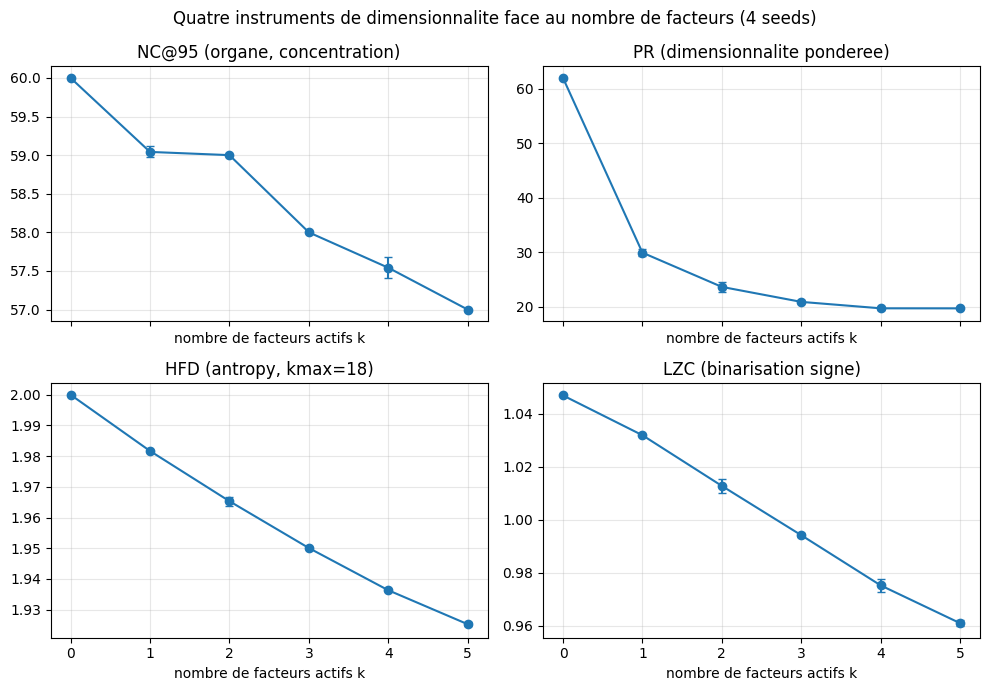

In [6]:
instruments = [("nc95", "NC@95 (organe, concentration)"),
               ("pr", "PR (dimensionnalite ponderee)"),
               ("hfd", "HFD (antropy, kmax=18)"),
               ("lzc", "LZC (binarisation signe)")]

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
for ax, (col, label) in zip(axes.flat, instruments):
    means = [np.mean([r[col] for r in rows if r["k"] == k]) for k in K_GRID]
    stds = [np.std([r[col] for r in rows if r["k"] == k]) for k in K_GRID]
    ax.errorbar(K_GRID, means, yerr=stds, marker="o", capsize=3)
    ax.set_title(label)
    ax.set_xlabel("nombre de facteurs actifs k")
    ax.grid(alpha=0.3)
fig.suptitle("Quatre instruments de dimensionnalite face au nombre de facteurs (4 seeds)")
fig.tight_layout()
plt.show()

### Lecture du resultat — verdict pre-enregistre

La mesure tranche, et elle tranche **dans le meme sens pour les quatre
instruments** — tous decroissent quand k augmente :

- **PR decroit** (62,0 sous bruit pur -> 30,0 a k=1 -> 19,7 a k=5) : c'est la
  dimensionalite effective ponderee de Shai et al., et sur ce terrain elle ne
  **compte pas** les facteurs. Au plancher de bruit eleve (63 directions de
  bruit a variance ~0,10 contre k directions a variance 1), chaque facteur
  partage ajoute de la variance concentree : le spectre se resserre, la
  participation ratio tombe. Le pole k = 0 est la « dimension maximale vide »
  (bruit isotrope : toutes directions egales, PR ~ D = 64).
- **NC@95 decroit** (60,0 -> 57,0) : meme mecanisme, lu par l'organe — plus de
  variance concentree sur peu de directions = moins de composantes pour 95 %.
- **HFD decroit** (2,00 -> 1,93) et **LZC decroit** (1,05 -> 0,96) : chaque
  canal additionne des facteurs AR persistants, donc devient temporellement
  plus regulier. Ce sont des instruments de **regularite temporelle par
  canal**.

**Ce que le pont etablit** : sur ce terrain, « ajouter un facteur latent
partage » fait baisser **les quatre** instruments de dimensionnalite/complexite
a la fois — aucun n'est un compteur croissant de facteurs. Consequence directe
pour la litterature : l'augmentation de HFD **et** de LZC raportee sous LSD
(Subramani et al. 2026) est **incoherente avec l'ajout de facteurs partages
persistants** (les quatre auraient baisse, comme mesure ici) et coherente avec
une **de-correlation** : plus d'independance temporelle par capteur, spectre
plus plat, regularite plus faible. Symetriquement, le « collapse dimensionnel »
des LLM (Shai et al. 2024) et l'« ouverture dimensionnelle » sous psychedele
sont tous deux des mouvements de PR — mais le sens du mouvement ne dit rien du
**nombre** de facteurs sans la reference au plancher de bruit, qui est ce que
la jambe SNR (exercice 2) fait varier.

## 6. Discrimination — tailles d'effet (discipline multi-seed)

L'objection « les courbes se touchent presque » se tranche mecaniquement : ecart k=5 vs k=1 en unites
d'ecart-type inter-seeds. Seuil maison : |effet| >= 2.

In [7]:
def effect_size(col):
    a = np.array([r[col] for r in rows if r["k"] == 5])
    b = np.array([r[col] for r in rows if r["k"] == 1])
    pooled = np.sqrt((a.std() ** 2 + b.std() ** 2) / 2.0)
    return float((a.mean() - b.mean()) / pooled)


for col, label in instruments:
    eff = effect_size(col)
    sens = "CROISSANT" if eff > 0 else "DECROISSANT"
    verdict = f"DETECTE_{sens}" if abs(eff) >= 2 else "NON_SEPARE"
    print(f"{label:<38} effet k5-vs-k1 = {eff:+6.2f} sigma  -> {verdict}")

NC@95 (organe, concentration)          effet k5-vs-k1 = -40.01 sigma  -> DETECTE_DECROISSANT
PR (dimensionnalite ponderee)          effet k5-vs-k1 = -20.82 sigma  -> DETECTE_DECROISSANT
HFD (antropy, kmax=18)                 effet k5-vs-k1 = -108.52 sigma  -> DETECTE_DECROISSANT
LZC (binarisation signe)               effet k5-vs-k1 = -90.81 sigma  -> DETECTE_DECROISSANT


## 7. Exercices

Trois exercices, a completer sans erreur volontaire : chaque stub s'execute tel quel (il affiche un
message et rend `None`), et la correction remplace le corps en conservant les etiquettes `# Etape N` et
`# TODO etudiant`.

### Exercice 1 — temoin bruit pur

La jambe k = 0 du balayage donne la HFD du bruit iid. Reproduis ce temoin de ton cote : la HFD moyenne
d'un terrain sans facteur doit se rassoir autour de la valeur du tableau (autour de 1.9-2.0), et tout
ecart durable signale un probleme de generation.

In [8]:
def hfd_bruit_pur(seed):
    """HFD moyenne (tous canaux, tous prompts) d'un terrain k=0.

    TODO etudiant
    """
    # Etape 1 : construire le terrain sans facteur avec build_terrain
    # Etape 2 : moyenner channel_hfd sur tous les prompts du terrain
    # Indice : build_terrain(0, seed)["prompts"].values() et channel_hfd
    print("Exercice 1 a completer")
    return None


hfd_bruit_pur(0)

Exercice 1 a completer


### Exercice 2 — facteur faible (jambe SNR)

Le balayage teste des facteurs d'amplitude egale. Que se passe-t-il quand le 5e facteur est **beaucoup
plus faible** (par exemple -12 dB relativement aux autres) ? Construis le terrain modifie et mesure PR et
HFD : lequel des deux detecte le facteur faible, lequel l'ignore ?

In [9]:
def terrain_facteur_faible(seed, snr_faible_db=-12.0):
    """Terrain a 4 facteurs forts + 1 facteur faible.

    TODO etudiant
    """
    # Etape 1 : construire un terrain k=4 avec build_terrain
    # Etape 2 : generer un 5e facteur AR(1) d'amplitude 10**(snr_faible_db/20)
    #           et l'ajouter aux residus via une colonne de loadings nouvelle
    # Etape 3 : mesurer effective_pr et channel_hfd, comparer au terrain k=4 seul
    # Indice : une colonne orthonormale de plus via make_loadings(d_model, 5)[:, 4]
    print("Exercice 2 a completer")
    return None


terrain_facteur_faible(0)

Exercice 2 a completer


### Exercice 3 — LZC : le choix de binarisation change-t-il la verdict ?

La LZC exige une binarisation ; la jambe principale prend le **signe**. Reprends la mesure avec la
binarisation par **mediane** (`resid[:, j] > mediane du canal`) : la valeur absolue change, mais la
**monotonie en k** survit-elle ?

In [10]:
def lzc_binarisation_mediane(resid):
    """LZC normalisee moyenne par canal, binarisation par mediane par canal.

    TODO etudiant
    """
    # Etape 1 : pour chaque canal, binariser par la mediane du canal
    # Etape 2 : appeler ent.lziv_complexity(..., normalize=True)
    # Etape 3 : verifier la monotonie en k sur K_GRID=[0, 1, 5] avec un seed
    # Indice : np.median(resid[:, j]) puis la meme boucle que channel_lzc
    print("Exercice 3 a completer")
    return None


lzc_binarisation_mediane(build_terrain(1, 0)["prompts"][("A", 0)]["resid"])

Exercice 3 a completer

## 8. Limites et suite

- **Terrain synthetique, verite exacte** : ce notebook etablit la reponse calibree des quatre
  instruments sur un GHMM a facteurs controles. Aucune donnee neurale n'a ete touchee.
- **Dataset MEG-17 : non etabli depuis ce siege** (mur anti-robot bioRxiv, OpenNeuro 404 — journalise dans
  le grain). L'archivage du PDF du papier dans le gisement bibliographique GDrive reste du. Le repli
  synthetique etait prevu par le protocole ; la jambe MEG reelle est l'etape suivante du grain multi-semaines.
- **HFD = temoin temporel, pas compteur** : la conclusion centrale (HFD decroit avec k sur ce terrain) est
  une propriete du terrain AR persistant — un terrain a facteurs **anti-correles** ou de rang spectral
  different pourrait inverser la tendance. C'est exactement le genre de variation que la suite du grain
  doit tester avant toute generalisation neuro.
- **Instruments non couverts** : le papier mesure aussi des connectivites inter-canaux ; aucun equivalent
  ici (hors perimetre de l'organe F-Lens, qui lit des sous-espaces, pas des graphes).

Grain [#20463](https://github.com/jsboige/CoursIA/issues/20463) — distillation Subramani et al. 2026 ;
parent pedagogique [ICT-36](ICT-36-FLens-FactoredGeometry-Python.ipynb) (accretion c) ; organes
`ict/flens_traces.py` et `ict/factor_geometry.py` consommes sans modification.